## Program 4

Employ a suitable high-dimensional dataset to create parallel coordinates plots and
scatterplot matrices for examining relationships among multiple features. Perform
PCA to reduce the data to 2D and 3D, and generate scree plots and cumulative
explained variance plots. Develop class-colored 2D and 3D PCA visualizations to
identify patterns, clusters, and underlying structures in the dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pandas.plotting import parallel_coordinates

# 1. Load the dataset
df = pd.read_csv('/content/Automobile_data.csv')

# Clean missing values ('?' is often used in this dataset for missing data)
df = df.replace('?', np.nan)

# Convert relevant columns to numeric
numeric_cols = ['normalized-losses', 'wheel-base', 'length', 'width', 'height',
                'curb-weight', 'engine-size', 'bore', 'stroke',
                'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with missing values in our features of interest to ensure clean visualization/PCA
features = ['wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'horsepower', 'city-mpg']
target = 'body-style' # We will use body-style as our class label

clean_df = df[features + [target]].dropna()

print(f"Dataset shape after cleaning: {clean_df.shape}")
display(clean_df.head())

Dataset shape after cleaning: (203, 9)


,wheel-base,length,width,height,curb-weight,engine-size,horsepower,city-mpg,body-style
0,88.6,168.8,64.1,48.8,2548,130,111.0,21,convertible
1,88.6,168.8,64.1,48.8,2548,130,111.0,21,convertible
2,94.5,171.2,65.5,52.4,2823,152,154.0,19,hatchback
3,99.8,176.6,66.2,54.3,2337,109,102.0,24,sedan
4,99.4,176.6,66.4,54.3,2824,136,115.0,18,sedan


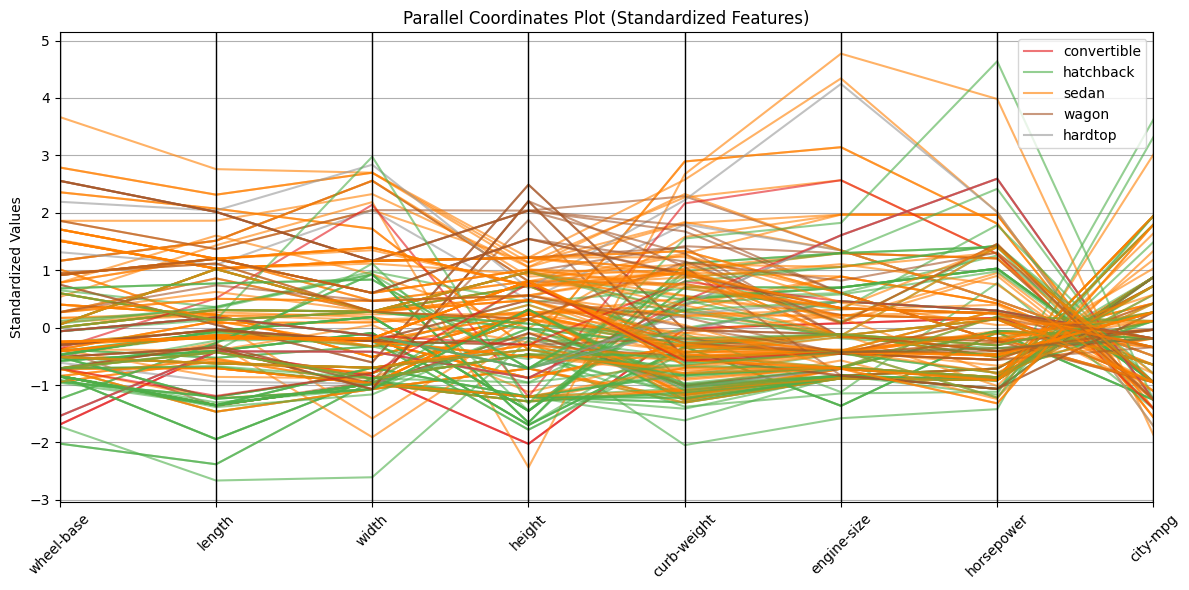

In [ ]:
# Standardize features before plotting parallel coordinates and PCA
scaler = StandardScaler()
scaled_features = scaler.fit_transform(clean_df[features])
scaled_df = pd.DataFrame(scaled_features, columns=features)
scaled_df[target] = clean_df[target].values

# 2. Parallel Coordinates Plot
plt.figure(figsize=(12, 6))
parallel_coordinates(scaled_df, class_column=target, colormap='Set1', alpha=0.6)
plt.title('Parallel Coordinates Plot (Standardized Features)')
plt.ylabel('Standardized Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

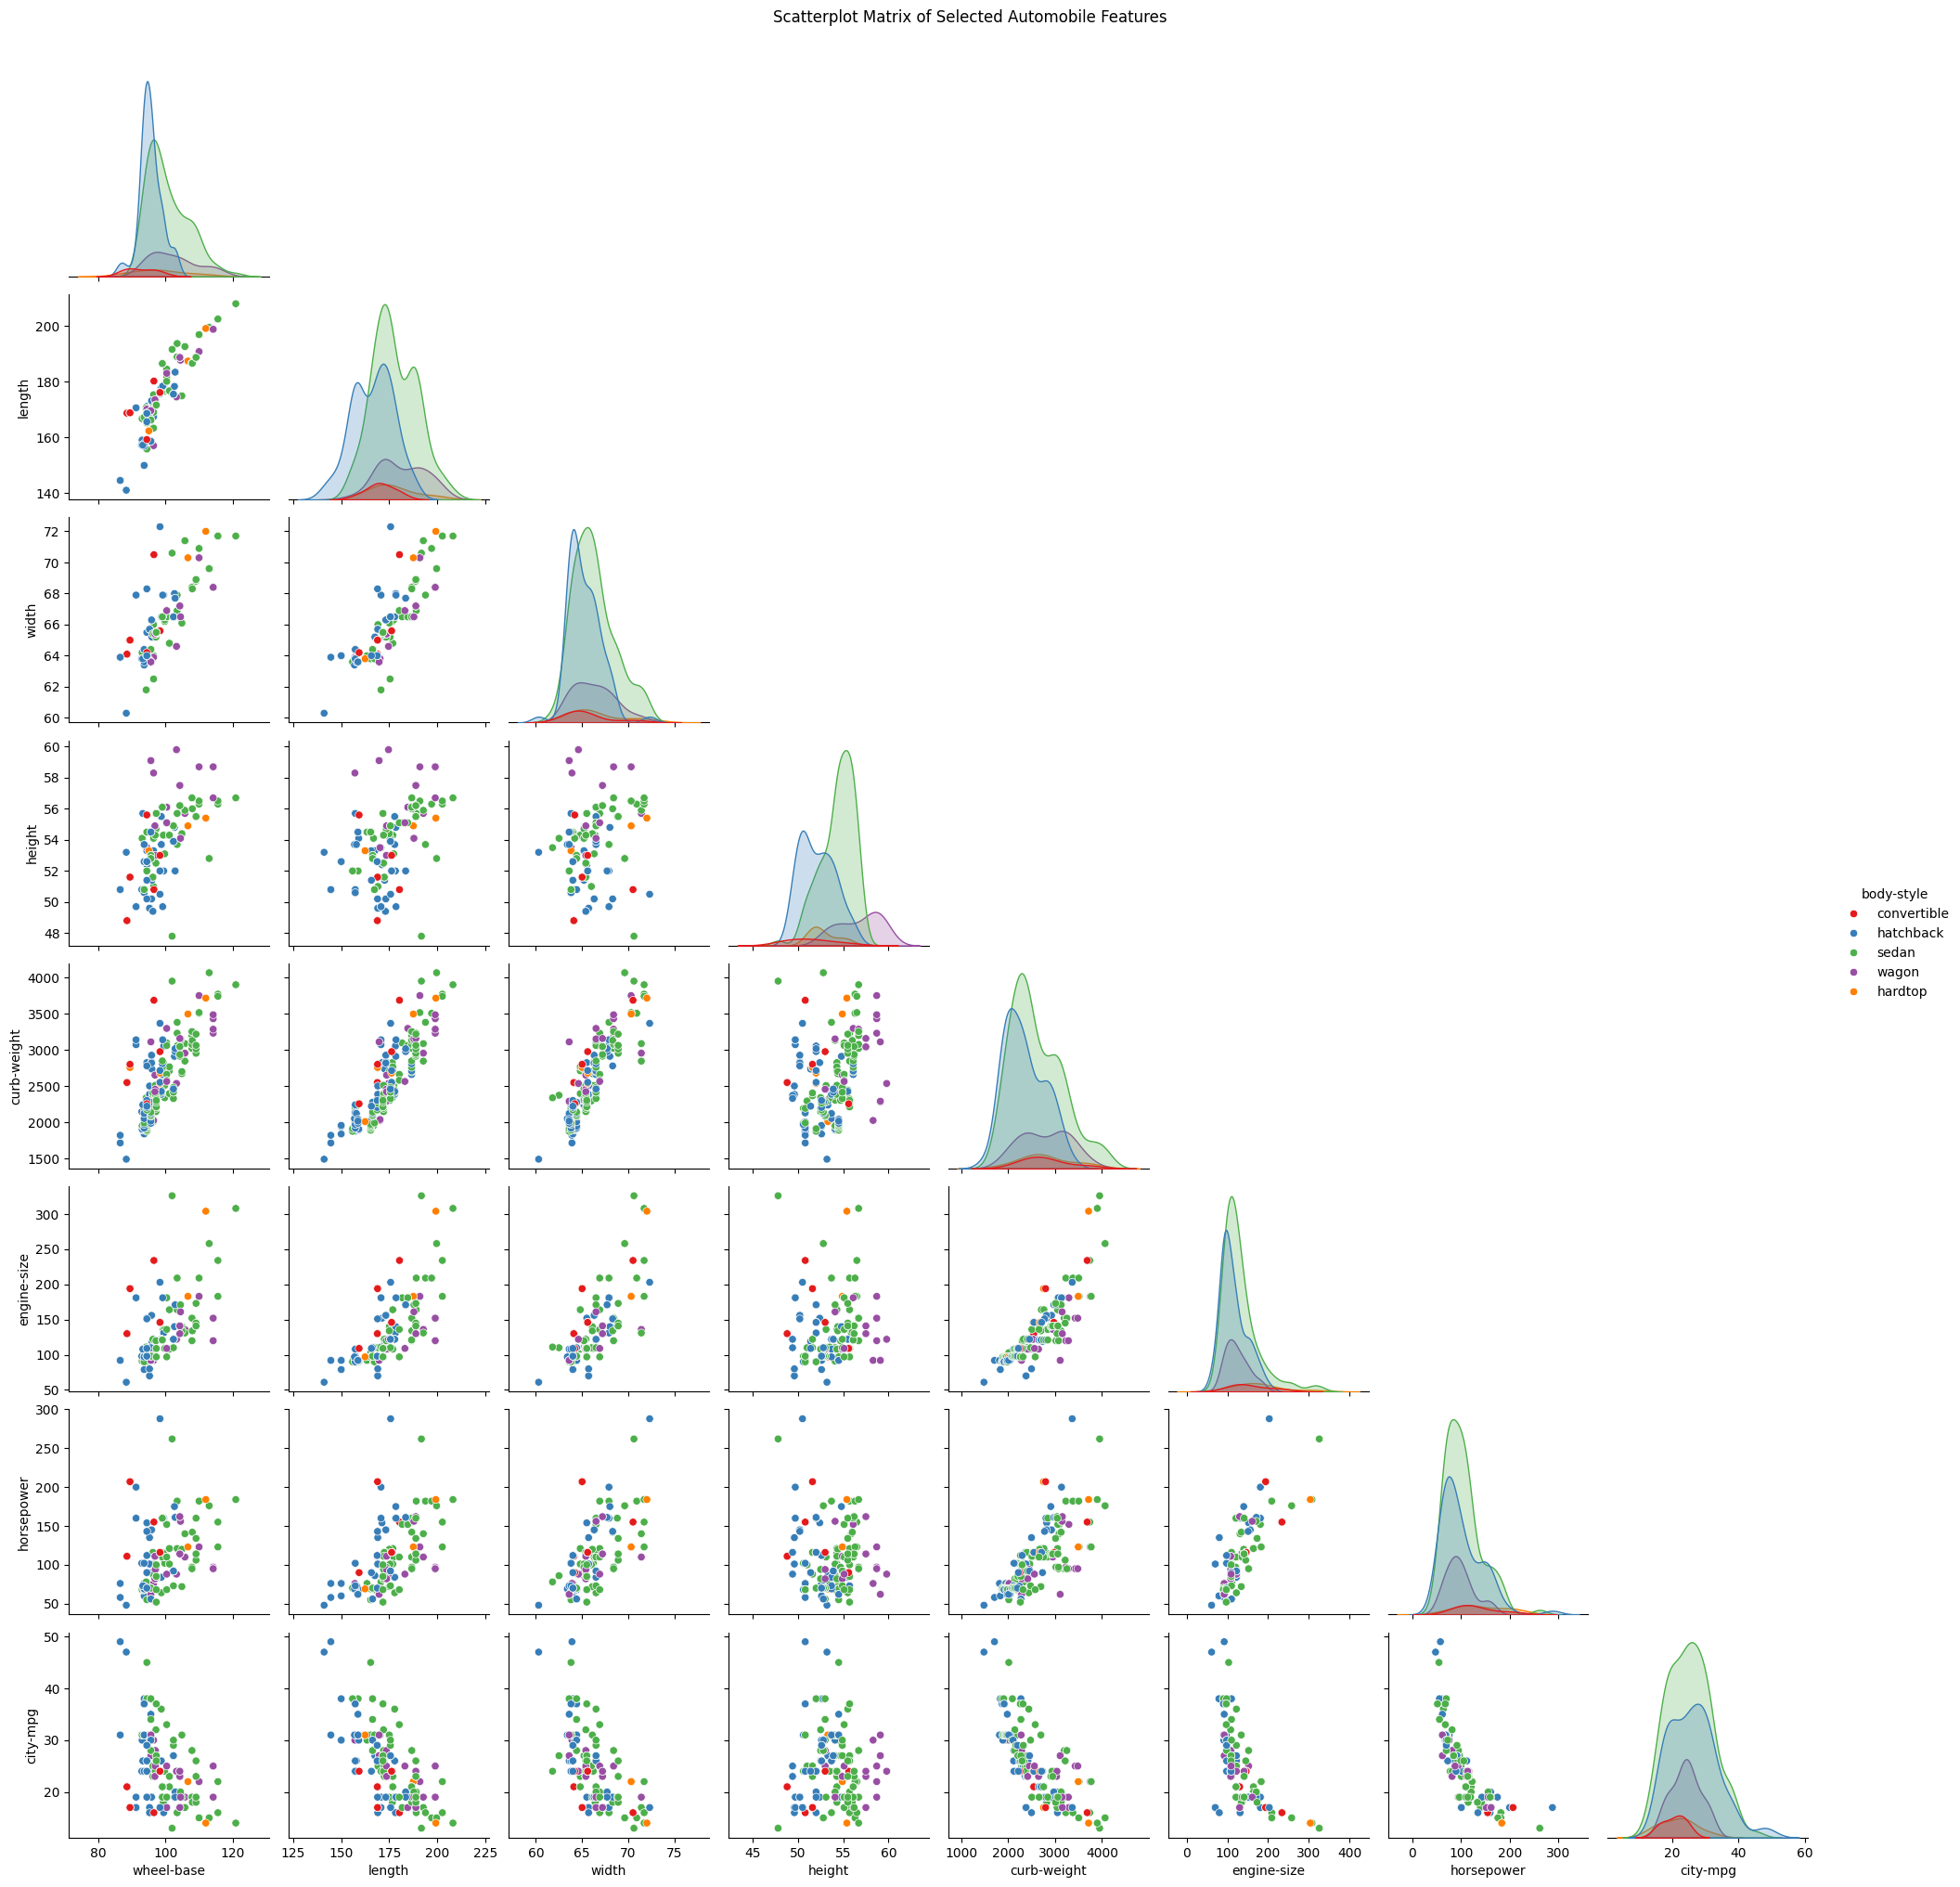

In [ ]:
# 3. Pairplot (Scatterplot Matrix)
sns.pairplot(clean_df, hue=target, palette='Set1', corner=True)
plt.suptitle('Scatterplot Matrix of Selected Automobile Features', y=1.02)
plt.show()

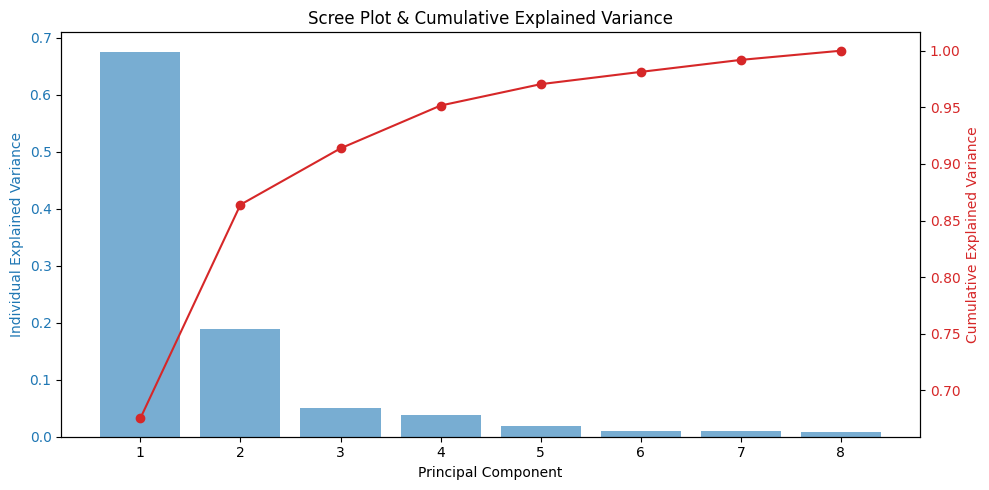

In [ ]:
# 4. PCA Analysis
pca_full = PCA()
pca_full.fit(scaled_features)

exp_var_ratio = pca_full.explained_variance_ratio_
cum_exp_var = np.cumsum(exp_var_ratio)

# Scree Plot & Cumulative Explained Variance Plot
fig, ax1 = plt.subplots(figsize=(10, 5))

# Scree Plot
color = 'tab:blue'
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Individual Explained Variance', color=color)
ax1.bar(range(1, len(exp_var_ratio) + 1), exp_var_ratio, alpha=0.6, color=color, label='Individual')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(range(1, len(exp_var_ratio) + 1))

# Cumulative Variance
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Cumulative Explained Variance', color=color)
ax2.plot(range(1, len(cum_exp_var) + 1), cum_exp_var, color=color, marker='o', label='Cumulative')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Scree Plot & Cumulative Explained Variance')
fig.tight_layout()
plt.show()

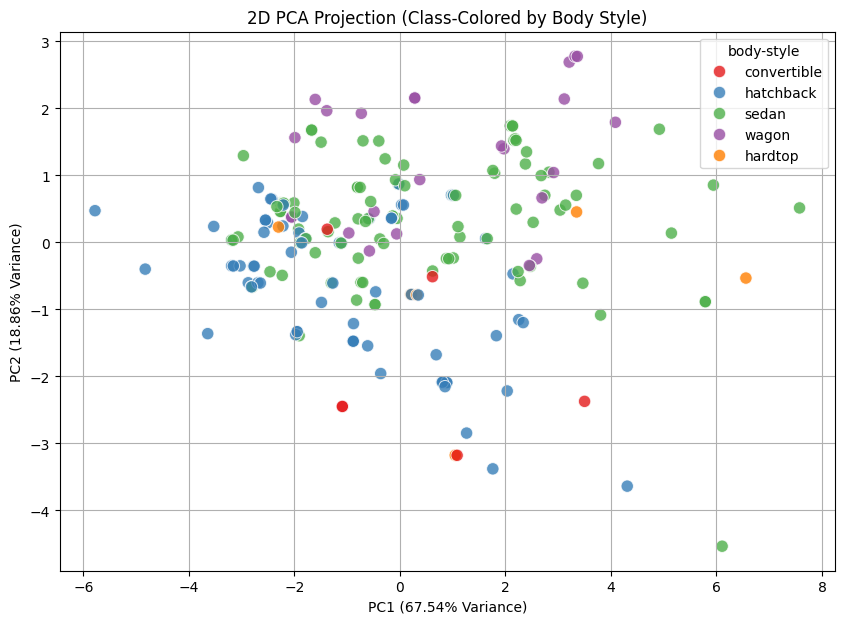

In [ ]:
# 5. 2D and 3D PCA Visualizations
pca_3d = PCA(n_components=3)
pca_projection = pca_3d.fit_transform(scaled_features)

pca_df = pd.DataFrame(data=pca_projection, columns=['PC1', 'PC2', 'PC3'])
pca_df[target] = clean_df[target].values

# 2D Plot
plt.figure(figsize=(10, 7))
sns.scatterplot(x='PC1', y='PC2', hue=target, data=pca_df, palette='Set1', s=80, alpha=0.8)
plt.title('2D PCA Projection (Class-Colored by Body Style)')
plt.xlabel(f'PC1 ({exp_var_ratio[0]*100:.2f}% Variance)')
plt.ylabel(f'PC2 ({exp_var_ratio[1]*100:.2f}% Variance)')
plt.grid(True)
plt.show()

/tmp/ipykernel_2340/2592608266.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('Set1', len(categories))


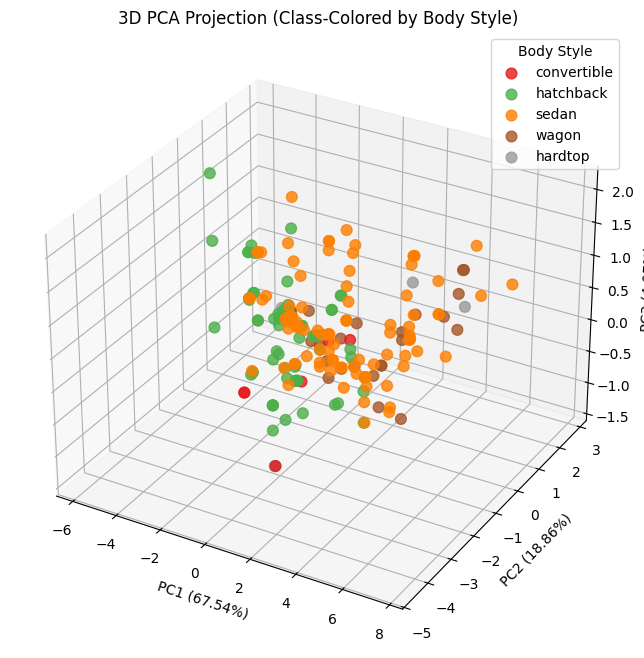

In [ ]:
# 3D Plot using Matplotlib
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Map categories to colors




categories = pca_df[target].unique()
colors = plt.cm.get_cmap('Set1', len(categories))
color_map = {cat: colors(i) for i, cat in enumerate(categories)}

for cat in categories:
    subset = pca_df[pca_df[target] == cat]
    ax.scatter(subset['PC1'], subset['PC2'], subset['PC3'],
               label=cat, s=60, alpha=0.8, color=color_map[cat])

ax.set_title('3D PCA Projection (Class-Colored by Body Style)')
ax.set_xlabel(f'PC1 ({exp_var_ratio[0]*100:.2f}%)')
ax.set_ylabel(f'PC2 ({exp_var_ratio[1]*100:.2f}%)')
ax.set_zlabel(f'PC3 ({exp_var_ratio[2]*100:.2f}%)')
ax.legend(title='Body Style')
plt.show()